<h4 align='center'>AEROPULSE</h4>
<h5 align='center'>AIRLINE OPERATIONS, DELAY & RELIABILITY ANALYTICS</h5>

<h5 align='center'>NOTEBOOK 06 - EDA</h5>


### Import Path

In [5]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_PATH = Path.cwd().parent

CLEANED_PATH = PROJECT_PATH / "04_Cleaned_Data"

TRANSFORMED_FILE = (
    CLEANED_PATH /
    "Aeropulse_Flights_January_2024_Cleaned.csv"
)

df = pd.read_csv(
    TRANSFORMED_FILE,
    low_memory=False
)

df["FlightDate"] = pd.to_datetime(
    df["FlightDate"],
    errors="coerce"
)

print("Rows:", f"{len(df):,}")
print("Columns:", len(df.columns))

Rows: 547,271
Columns: 93


In [6]:
df.groupby("FlightDate").size()

Series([], dtype: int64)

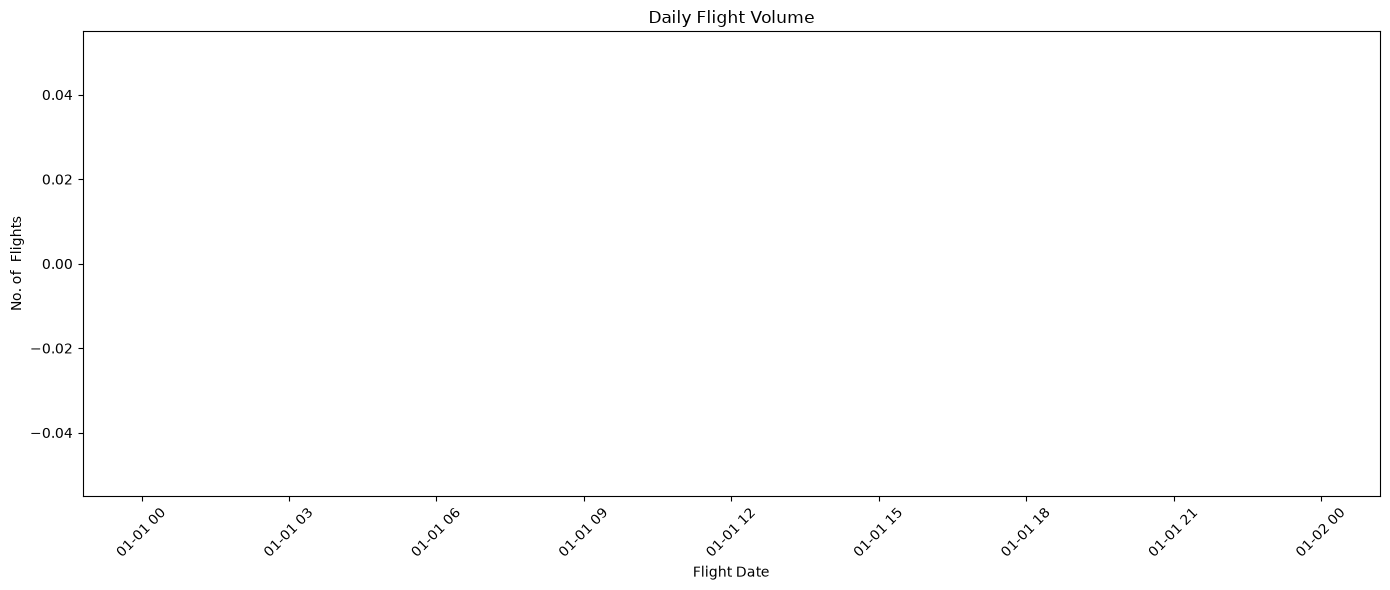

In [7]:
daily_flights = (
    df.groupby("FlightDate")
    .size()
    .reset_index(name="Flight_Counts")
)

plt.figure(figsize=(14, 6))

plt.plot(daily_flights["FlightDate"], daily_flights["Flight_Counts"])

plt.title("Daily Flight Volume")

plt.xlabel("Flight Date")

plt.ylabel("No. of  Flights")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

In [8]:
df["Reporting_Airline"].value_counts()

Reporting_Airline
WN    115389
AA     77346
DL     74384
UA     58855
OO     56814
YX     22914
MQ     20750
NK     20415
B6     19580
AS     17775
9E     16972
OH     16526
F9     14379
G4      8596
HA      6576
Name: count, dtype: int64

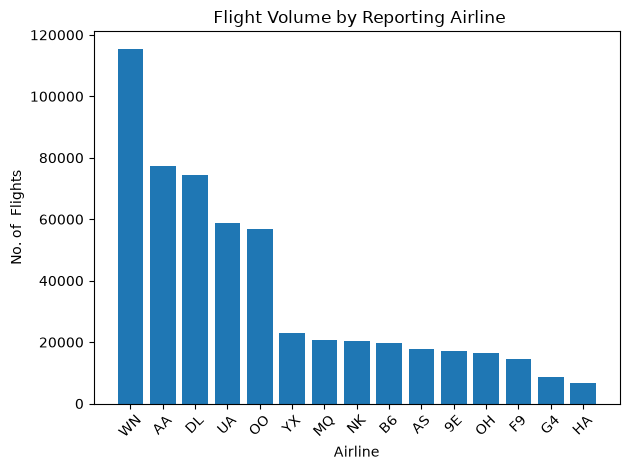

In [9]:
total_airline = (
    df["Reporting_Airline"]
    .value_counts()
)

plt.bar(total_airline.index, total_airline.values)
plt.title(" Flight Volume by Reporting Airline")

plt.xlabel("Airline")

plt.ylabel("No. of  Flights")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

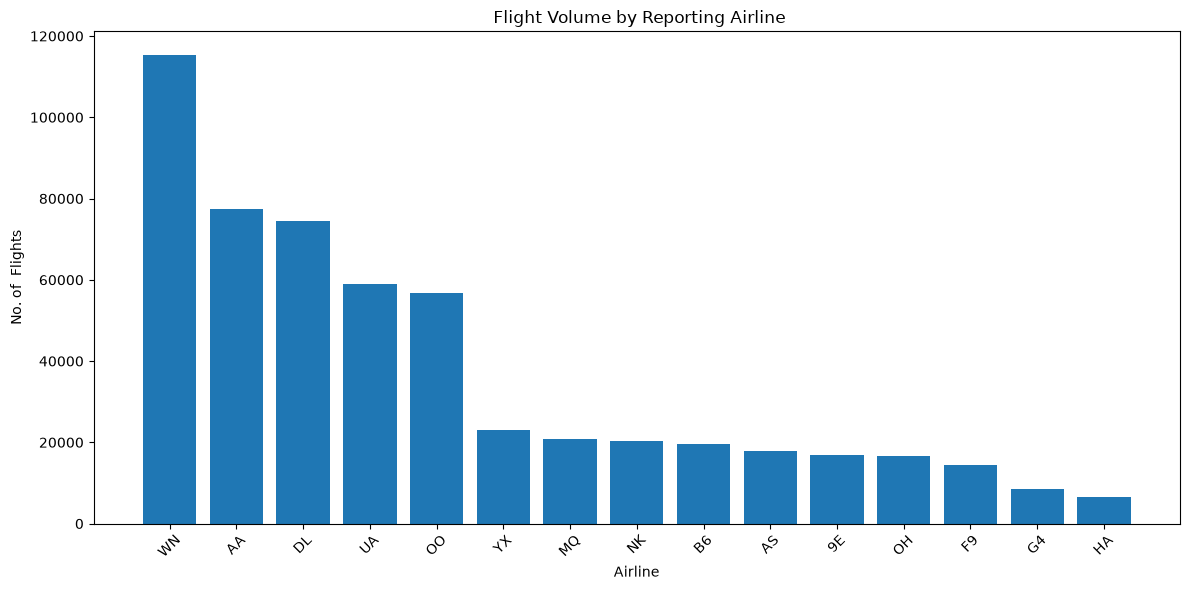

In [10]:
plt.figure(figsize=(12, 6))

total_airline = (
    df["Reporting_Airline"]
    .value_counts()
)

plt.bar(total_airline.index, total_airline.values)
plt.title(" Flight Volume by Reporting Airline")

plt.xlabel("Airline")

plt.ylabel("No. of  Flights")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

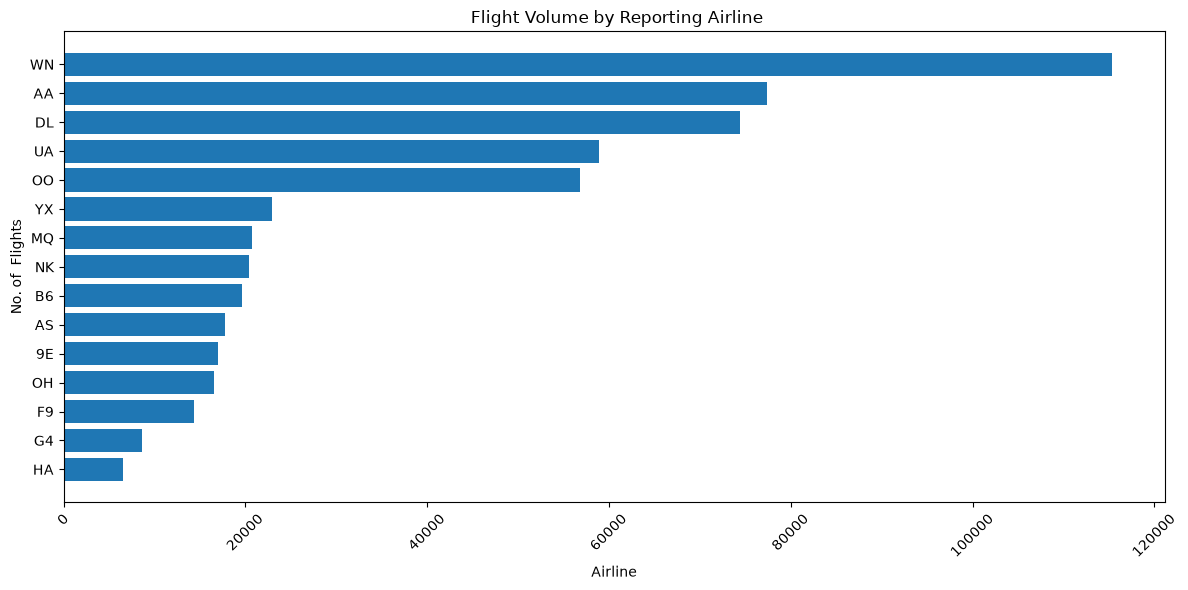

In [11]:
plt.figure(figsize=(12, 6))

total_airline = (
    total_airline.sort_values()
)

plt.barh(total_airline.index, total_airline.values)
plt.title(" Flight Volume by Reporting Airline")

plt.xlabel("Airline")

plt.ylabel("No. of  Flights")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

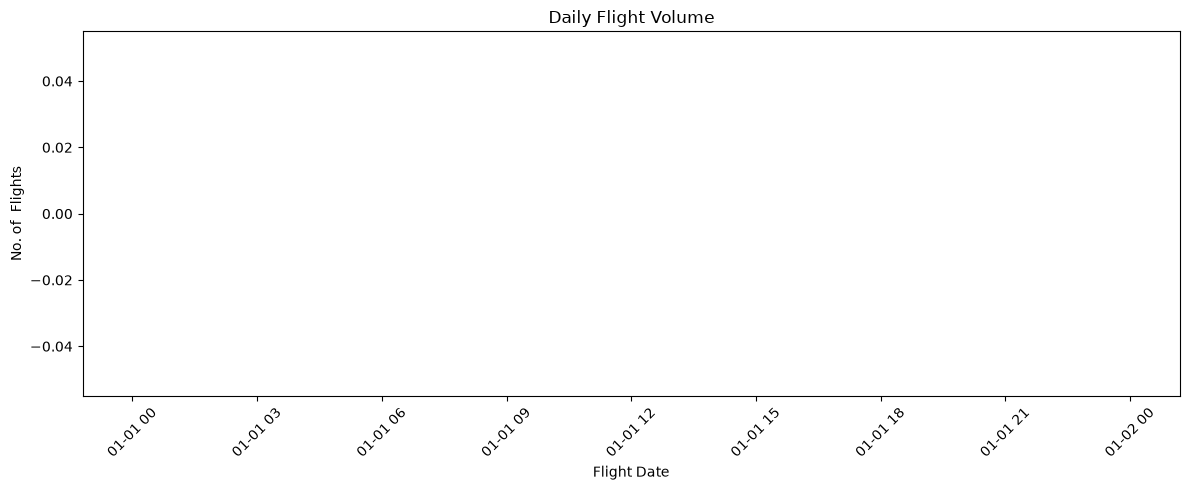

In [12]:
daily_airline =(
    df.groupby(["FlightDate", "Reporting_Airline"])
    .size()
    .reset_index(name="Flight_Counts")
)

top_airlines = (
    df["Reporting_Airline"]
    .value_counts()
    .head(5)
    .index
)

plt.figure(figsize=(12, 5))

for airline in top_airlines:

    temp = daily_airline[daily_airline["Reporting_Airline"] == airline]

    plt.plot(temp["FlightDate"], temp["Flight_Counts"], label= airline)

plt.title("Daily Flight Volume")

plt.xlabel("Flight Date")

plt.ylabel("No. of  Flights")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

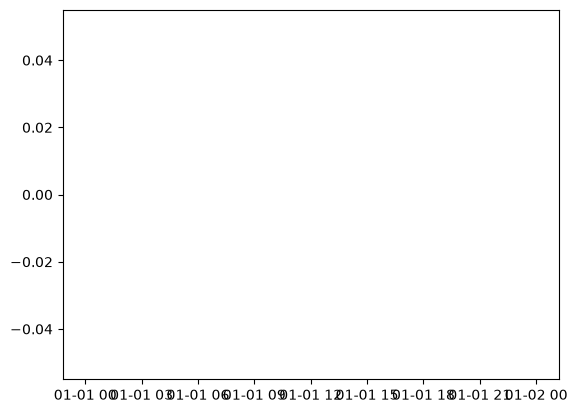

In [13]:
daily_airline =(
    df.groupby(["FlightDate", "Reporting_Airline"])
    .size()
    .reset_index(name="Flight_Counts")
)

top_airlines = (
    df["Reporting_Airline"]
    .value_counts()
    .head(5)
    .index
)

for airline in top_airlines:

    temp = daily_airline[daily_airline["Reporting_Airline"] == airline]

    plt.plot(temp["FlightDate"], temp["Flight_Counts"], label= airline)

plt.show()

Text(0, 0.5, 'No of Flights')

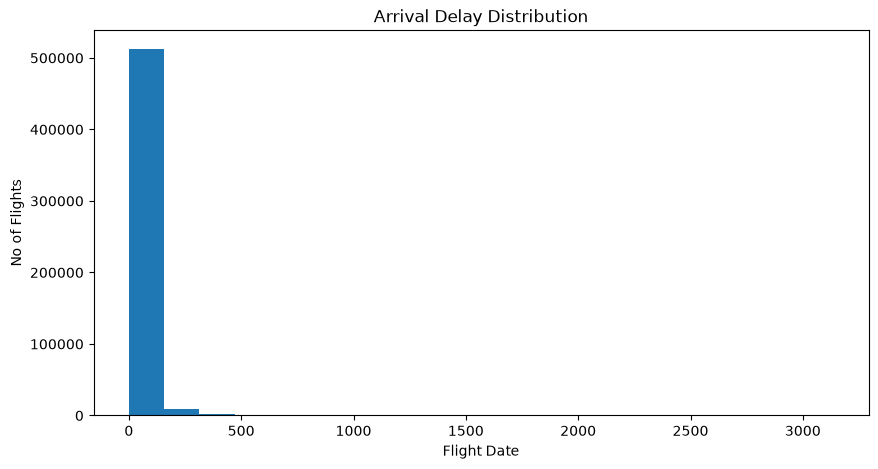

In [14]:
plt.figure(figsize=(10, 5))

arrival_delay = (
    df["ArrDelayMinutes"]
    .dropna()
)

plt.hist(arrival_delay, bins=20)

plt.title("Arrival Delay Distribution")

plt.xlabel("Flight Date")

plt.ylabel("No of Flights")

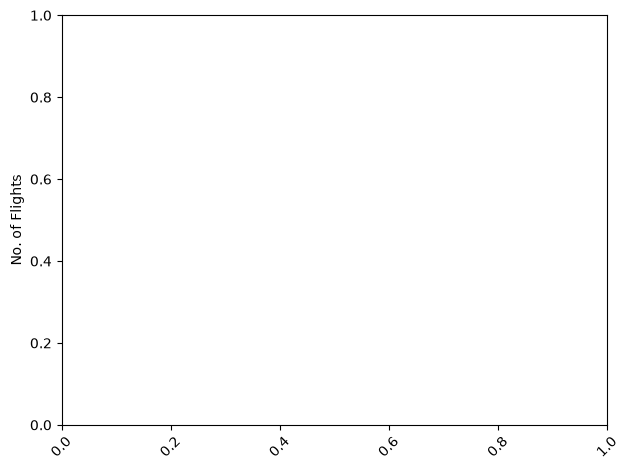

In [15]:
plt.ylabel("No. of Flights")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

C:\Users\bhaje\AppData\Local\Temp\ipykernel_22648\4136404036.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(arrival_delay, vert=False)


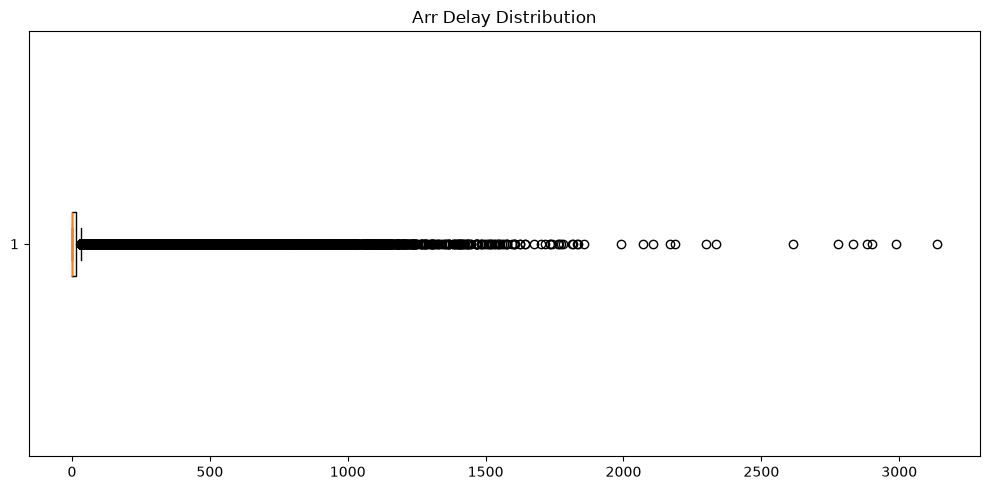

In [16]:
plt.figure(figsize=(10, 5))

plt.boxplot(arrival_delay, vert=False)

plt.title("Arr Delay Distribution")

plt.tight_layout()

plt.show()

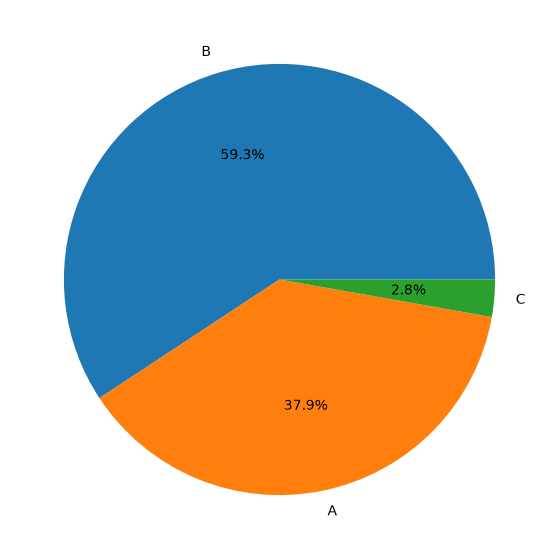

In [17]:
cancellation_status = (
    df["CancellationCode"]
    .value_counts()
)

plt.figure(figsize=(7, 7))

plt.pie(cancellation_status.values, labels=cancellation_status.index, autopct="%1.1f%%")
plt.show()

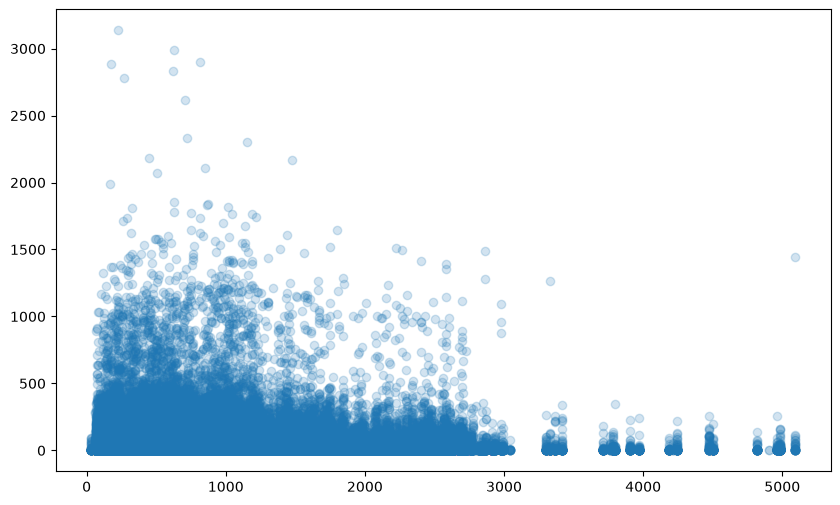

In [18]:
scatter_data = (
    df[["Distance", "ArrDelayMinutes"]].dropna()
)

plt.figure(figsize=(10,6))
plt.scatter(scatter_data["Distance"], scatter_data["ArrDelayMinutes"], alpha=0.2)
plt.show()

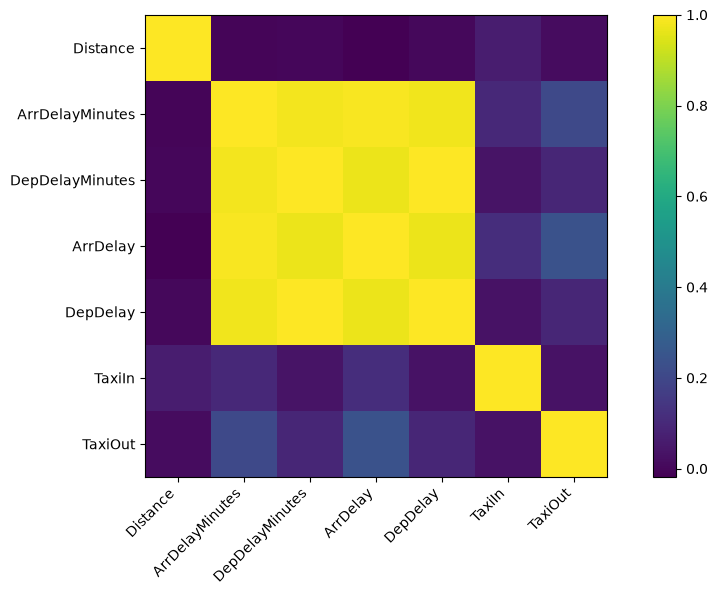

In [19]:
corr_columns = [
    "Distance",
    "ArrDelayMinutes",
    "DepDelayMinutes",
    "ArrDelay",
    "DepDelay",
    "TaxiIn",
    "TaxiOut"
]

corr_columns = [c for c in corr_columns if c in df.columns]

corr = df[corr_columns].corr()

plt.figure(figsize=(12, 6))

plt.imshow(corr, interpolation="nearest")

plt.colorbar()

plt.xticks(
    range(len(corr_columns)),
    corr_columns,
    rotation = 45,
    ha="right"
)

plt.yticks(
    range(len(corr_columns)),
    corr_columns,
)

plt.show()

C:\Users\bhaje\AppData\Local\Temp\ipykernel_22648\1245053597.py:6: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax[1].boxplot(arrival_delay, vert=False)


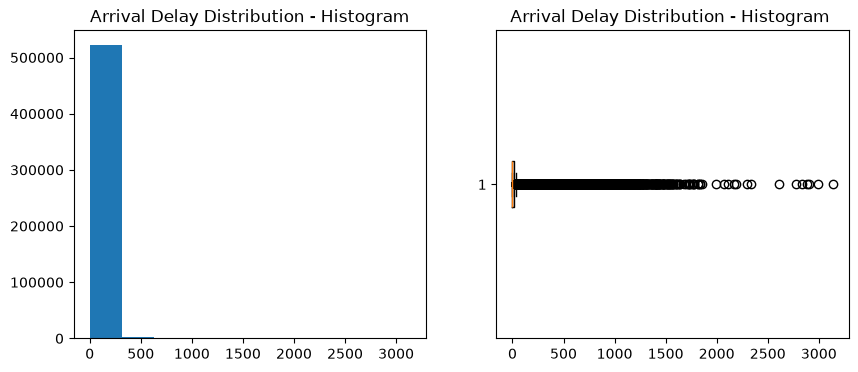

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].hist(arrival_delay, bins=10)
ax[0].set_title("Arrival Delay Distribution - Histogram")

ax[1].boxplot(arrival_delay, vert=False)
ax[1].set_title("Arrival Delay Distribution - Histogram ")

plt.show()

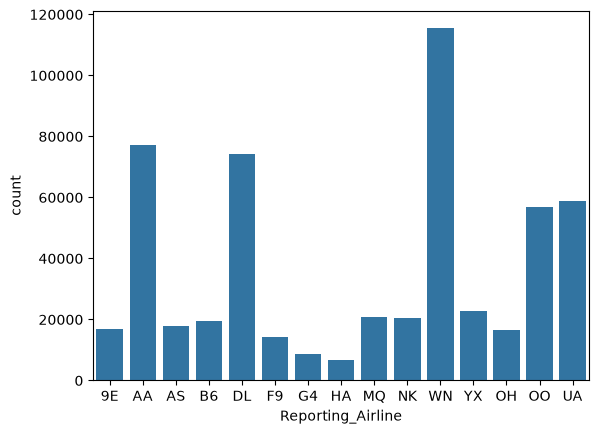

In [21]:
sns.countplot(data=df, x='Reporting_Airline')
plt.show()

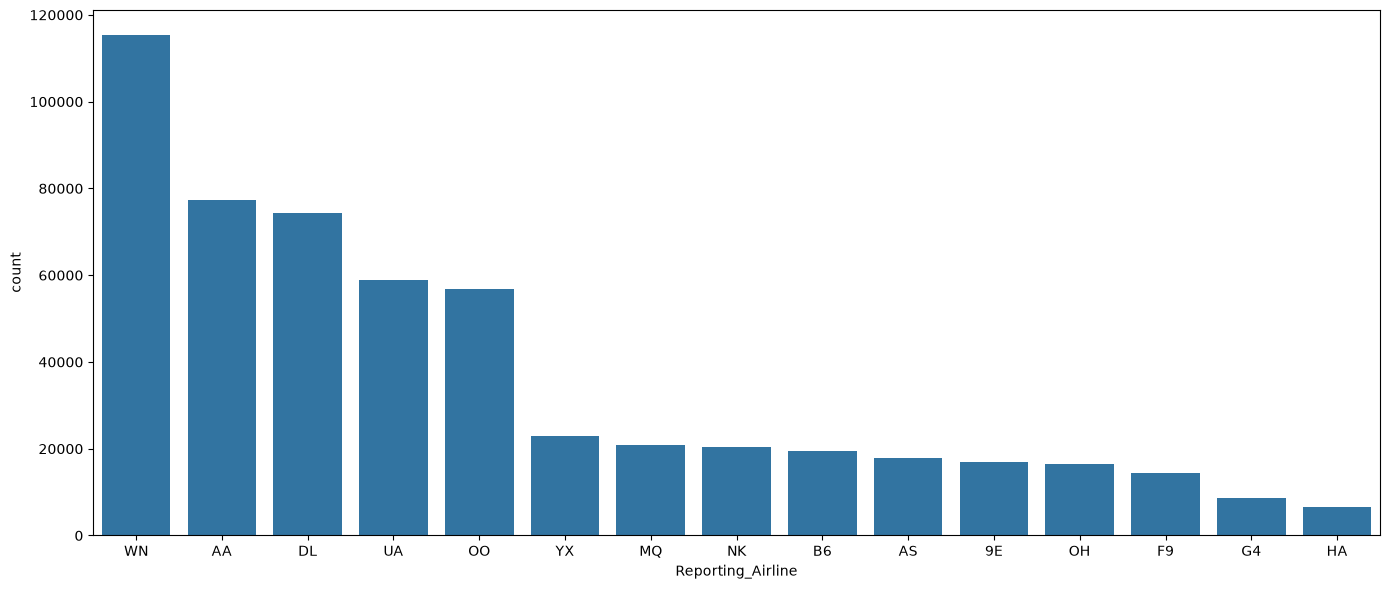

In [22]:
plt.figure(figsize=(14, 6))

sns.countplot(data=df, x="Reporting_Airline",
              order=df["Reporting_Airline"].value_counts(ascending=False).index
              )
plt.tight_layout()
plt.show()

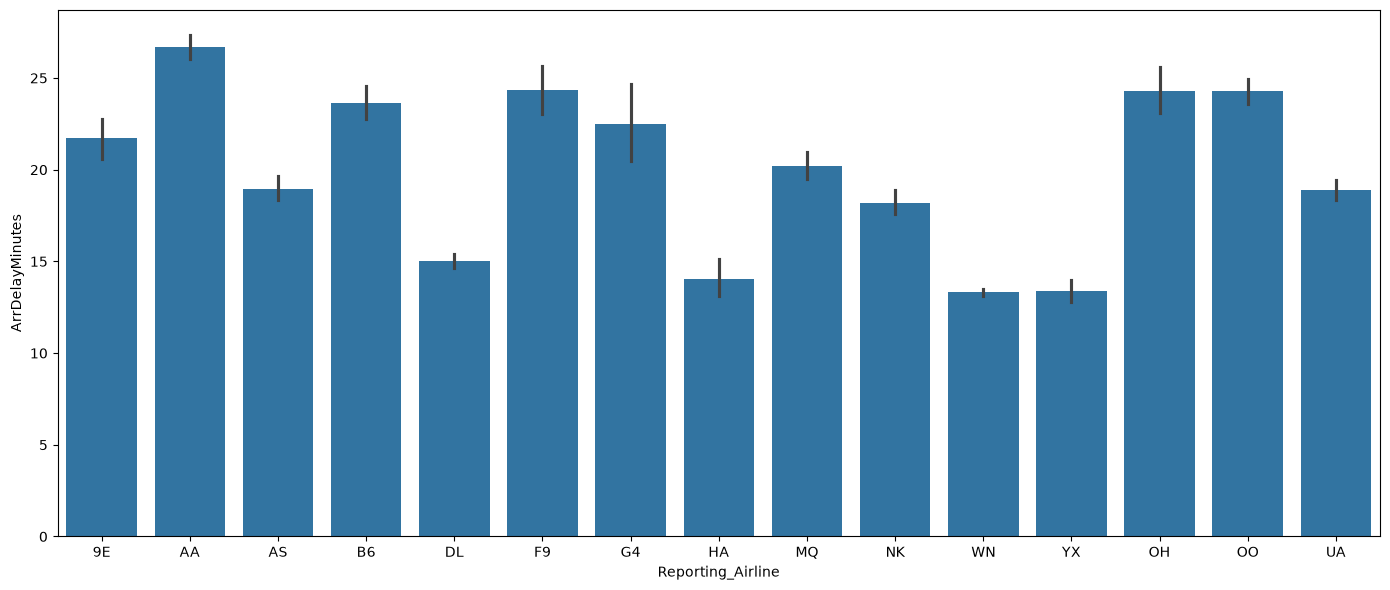

In [27]:
plt.figure(figsize=(14, 6))

sns.barplot(data=df, x="Reporting_Airline", y="ArrDelayMinutes")

plt.tight_layout()
plt.show()

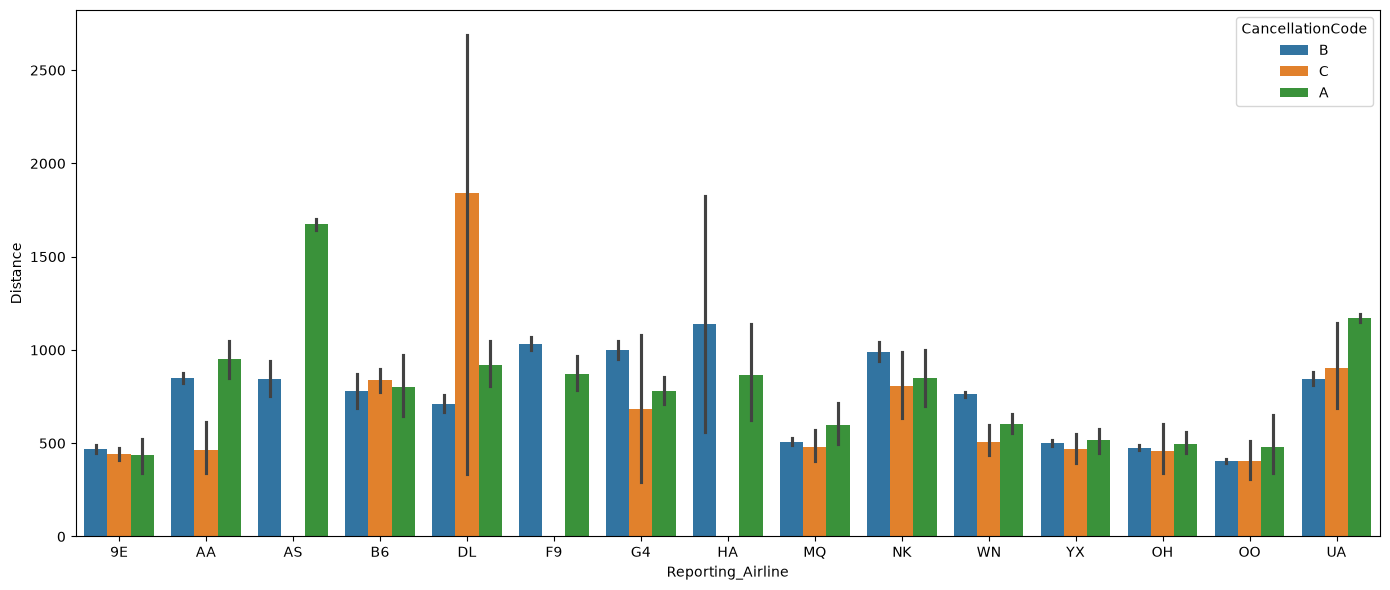

In [26]:
plt.figure(figsize=(14, 6))

sns.barplot(data=df, x="Reporting_Airline", y="Distance", hue="CancellationCode")

plt.tight_layout()
plt.show()

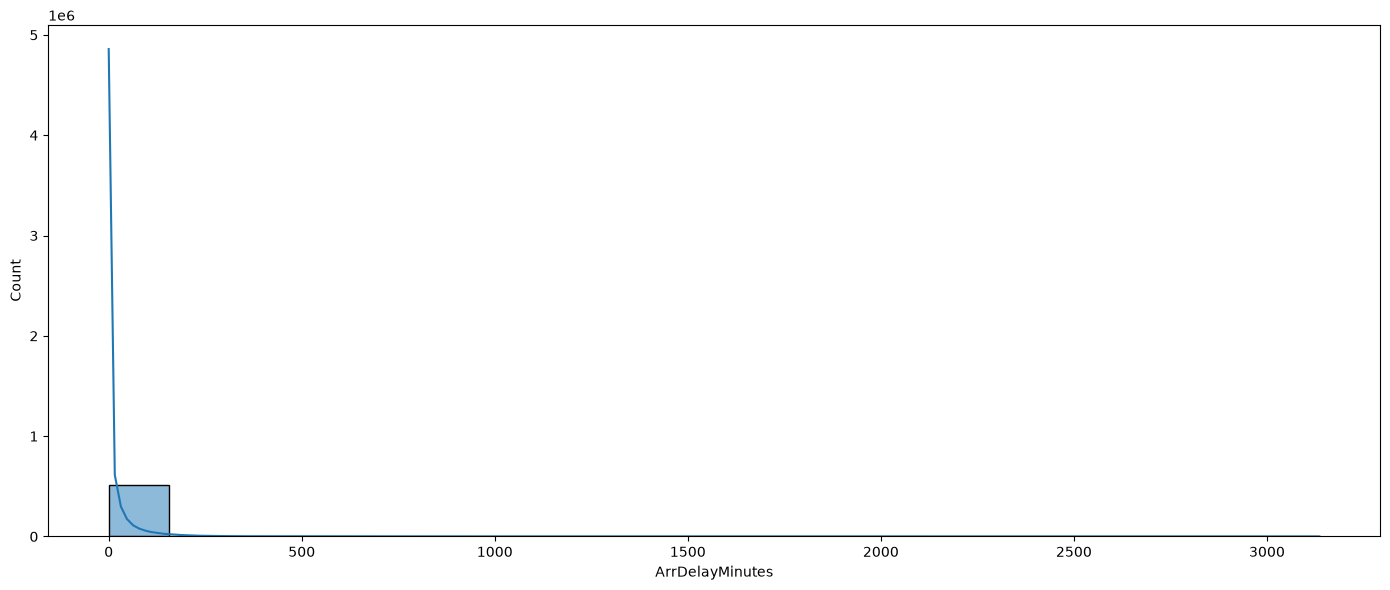

In [31]:
plt.figure(figsize=(14, 6))

sns.histplot(data=df, x="ArrDelayMinutes", bins=20, kde=True)

plt.tight_layout()
plt.show()


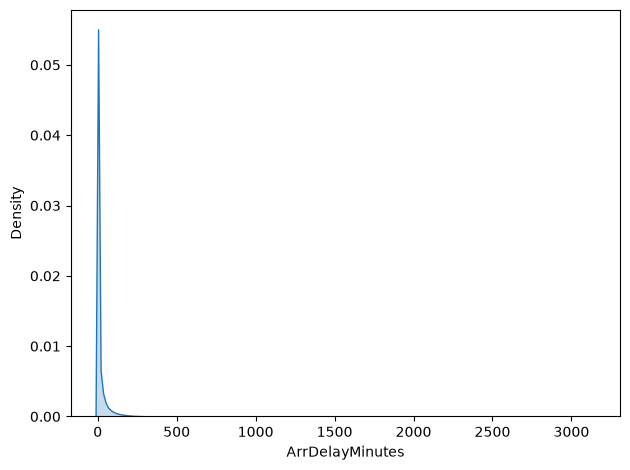

In [32]:
plt.Figure(figsize=(14, 6))

sns.kdeplot(data=df, x="ArrDelayMinutes", fill=True)
plt.tight_layout()
plt.show()


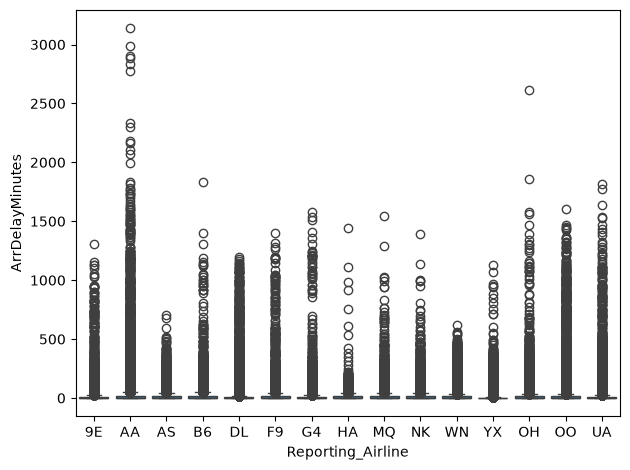

In [34]:
plt.Figure(figsize=(14, 6))

sns.boxplot(data=df, x="Reporting_Airline", y="ArrDelayMinutes")

plt.tight_layout()
plt.show()


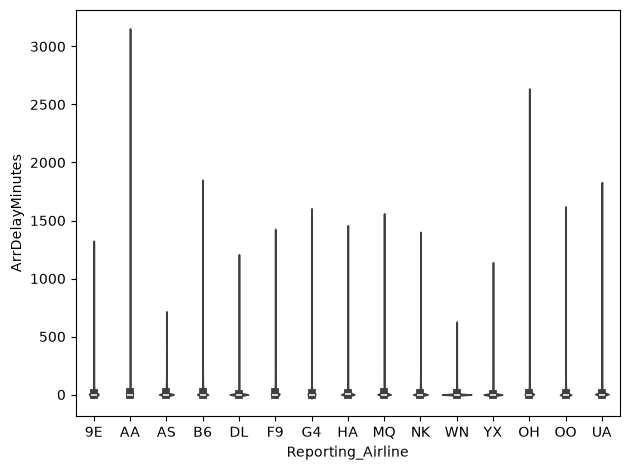

In [ ]:
plt.Figure(figsize=(14, 6))

sns.boxplot(data=df, x="Reporting_Airline", y="ArrDelayMinutes")

plt.tight_layout()
plt.show()


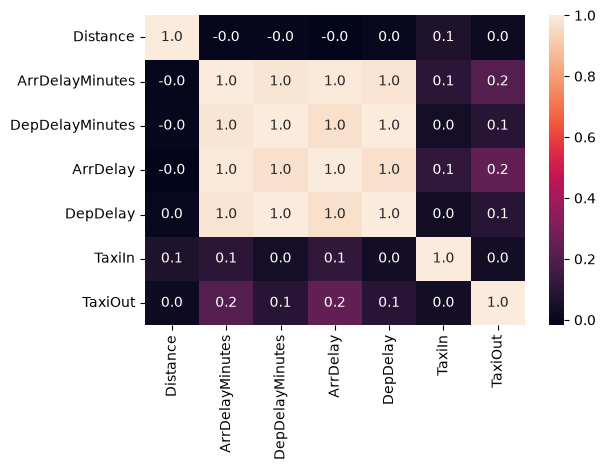

In [40]:
plt.Figure(figsize=(14, 6))

sns.heatmap(corr, annot=True, fmt=".1f")

plt.tight_layout()
plt.show()


In [44]:
relation = (df[["Distance", "ArrDelayMinutes"]]
 .dropna()
 .sample(min(5000, len(df)))
 )

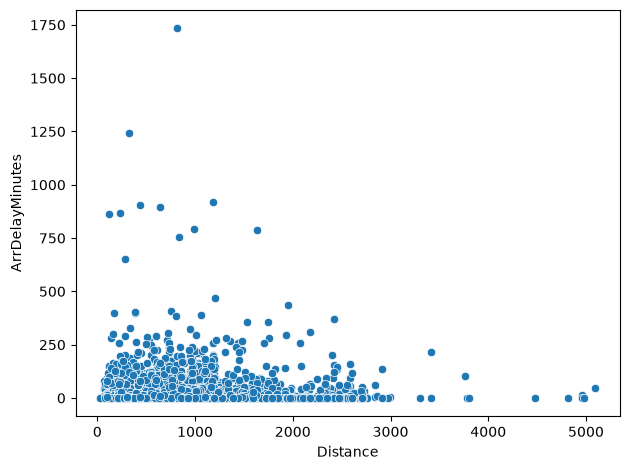

In [ ]:
plt.Figure(figsize=(14, 6))

sns.scatterplot(x=relation["Distance"], y=relation["ArrDelayMinutes"])

plt.tight_layout()
plt.show()


In [46]:
relation = (df[["Distance", "ArrDelayMinutes", "Reporting_Airline"]]
 .dropna()
 .sample(min(5000, len(df)))
 )

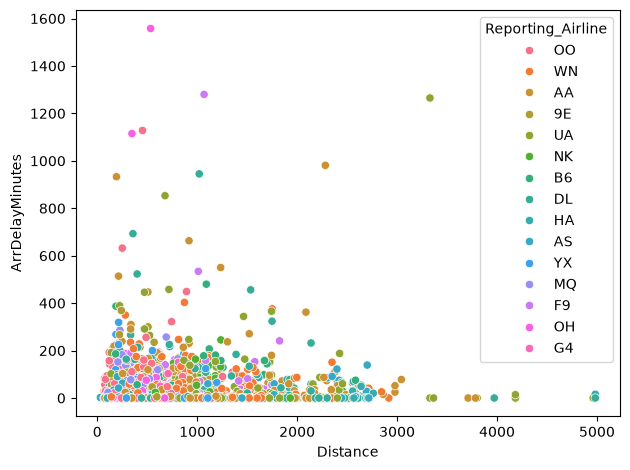

In [47]:
plt.Figure(figsize=(14, 6))

sns.scatterplot(data=relation, x=relation["Distance"], y=relation["ArrDelayMinutes"], hue="Reporting_Airline")

plt.tight_layout()
plt.show()


In [52]:
# plt.Figure(figsize=(14, 6))

# sns.swarmplot(data=relation, x="ArrDelayMinutes", y="Distance")

# plt.tight_layout()
# plt.show()


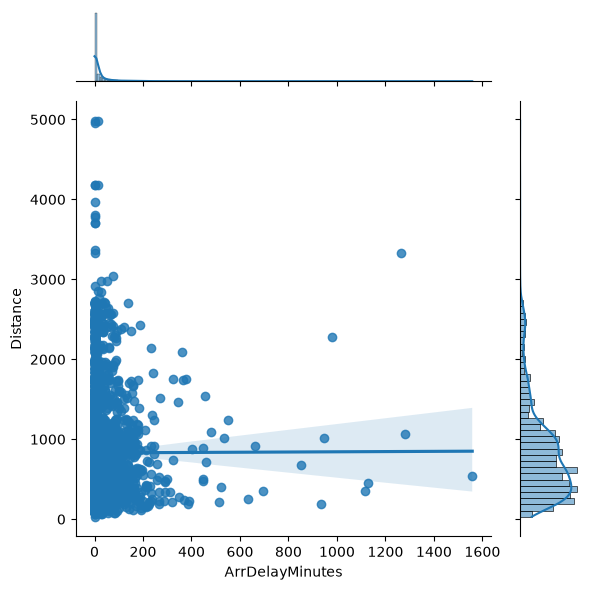

In [53]:
plt.Figure(figsize=(14, 6))

sns.jointplot(data=relation, x="ArrDelayMinutes", y="Distance", kind="reg")

plt.tight_layout()
plt.show()
